In [138]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency

#### Premières infos

In [139]:
df = pd.read_csv("jackstream_acm.csv",
                 sep=";", decimal=",")

df_base = df.set_index("ID_utilisateur") 
 
df_base.info()    
display(df_base)

<class 'pandas.DataFrame'>
Index: 1200 entries, JS0001 to JS1200
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Heures_semaine     1200 non-null   float64
 1   Abonnement         1200 non-null   str    
 2   Genre_prefere      1200 non-null   str    
 3   Appareil           1200 non-null   str    
 4   Moment_visionnage  1200 non-null   str    
 5   Partage_compte     1200 non-null   str    
dtypes: float64(1), str(5)
memory usage: 65.6+ KB


,Heures_semaine,Abonnement,Genre_prefere,Appareil,Moment_visionnage,Partage_compte
ID_utilisateur,,,,,,
JS0001,6.5,Essentiel,Sport,Smartphone,Trajets,Solo
JS0002,7.5,Essentiel,Animation,Tablette,Soiree,Famille_elargie
JS0003,12.9,Famille,Animation,Tablette,Soiree,Famille_elargie
JS0004,3.8,Essentiel,Films,Smartphone,Trajets,Solo
JS0005,6.7,Gratuit,Films,Box_TV,Week-end,Solo
...,...,...,...,...,...,...
JS1196,19.2,Famille,Documentaires,TV_connectee,Apres-midi,Couple
JS1197,11.6,Essentiel,Documentaires,Smartphone,Soiree,Colocation
JS1198,12.0,Essentiel,Sport,Smartphone,Soiree,Amis


In [140]:
print(df_base.shape)
print(df_base.isna().sum().sum())
print(df.duplicated().sum())
# Bien le faire avec que ID_utilisateur ne devienne l'index (c'est le cas de df_base) car duplicated compare seulement sur les colonnes, et non sur l'index 
# ⇒ donc l'ID_utilisateur ne fais plus la différentciation et des duplicats apparaissent car même donées dans reste colonnes.

print(df_base.index.duplicated().sum())

(1200, 6)
0
0
0


##### voir le masque des valeurs manquantes sur df_base (car ID_utilisateur ne fait plus l'unicité) sur on df de départ

In [141]:
masque = df_base.duplicated(keep=False)

# print(df_base.loc[masque])         
print(df.loc[masque.to_numpy()])    # Affiche les lignes correspondantes de df

     ID_utilisateur  Heures_semaine Abonnement Genre_prefere    Appareil  \
78           JS0079             2.2    Gratuit         Films  Smartphone   
88           JS0089             1.0    Gratuit         Films  Smartphone   
112          JS0113             2.1  Essentiel         Films      Box_TV   
126          JS0127             7.8  Essentiel         Sport      Box_TV   
137          JS0138             3.3  Essentiel         Films  Smartphone   
168          JS0169             2.2    Gratuit         Films  Smartphone   
204          JS0205            13.8    Famille     Animation    Tablette   
210          JS0211             6.0    Famille     Animation  Smartphone   
255          JS0256             2.6  Essentiel         Sport      Box_TV   
278          JS0279             3.3  Essentiel         Films  Smartphone   
319          JS0320             7.8  Essentiel         Sport      Box_TV   
329          JS0330            12.1    Gratuit         Films  Smartphone   
583         

### Problématique : quels profils d'usage coexistent sur la plateforme ? 

#### ACM = analyse des correspondances multiples pour données qualitatives (catégorielles)

Elle permet d'étudier plus de deux variables simultanément, contrairement à l'analyse factorielle des correspondances (AFC). Un exemple typique de données utilisées en ACM est celui des enquêtes d’opinion.  

C'est une analyse des correspondances appliquée au tableau disjonctif complet (sur des données catégorielles transformées en tableau binaire).  

*Tableau disjonctif =  transforme les réponses catégorielles en colonnes binaires — 1 si une personne possède une modalité, 0 sinon*

#### Variables sont qualitatives (sauf 1, *cf.* suite)

In [142]:
var_qualitatives = ["Abonnement", "Genre_prefere", "Appareil",
         "Moment_visionnage", "Partage_compte"]
for v in var_qualitatives:
    print((df_base[v].value_counts(normalize=True)*100).round(2))
    # print((df_base[v].value_counts(normalize=True)*100).sum()) fait bien 100 %
    print("-" * 50)

Abonnement
Essentiel    23.75
Premium      21.17
Famille      18.75
Standard     18.25
Gratuit      18.08
Name: proportion, dtype: float64
--------------------------------------------------
Genre_prefere
Sport            23.92
Documentaires    21.00
Films            19.08
Series           18.42
Animation        17.58
Name: proportion, dtype: float64
--------------------------------------------------
Appareil
Box_TV          22.83
TV_connectee    20.58
Smartphone      19.25
Tablette        17.42
Ordinateur      16.83
Console          3.08
Name: proportion, dtype: float64
--------------------------------------------------
Moment_visionnage
Apres-midi    22.33
Trajets       21.25
Soiree        20.33
Week-end      18.33
Nuit          17.75
Name: proportion, dtype: float64
--------------------------------------------------
Partage_compte
Amis               23.17
Couple             21.25
Solo               20.33
Famille_elargie    19.33
Colocation         15.92
Name: proportion, dtype: float

Tri à plat révèle les modalités rares comme la console à 3,08 %

#### Une seule variable quantitative ici, en float, les heures d'utilisation par semaine

In [143]:
df_base.describe().round(2) 

,Heures_semaine
count,1200.00
mean,12.71
std,8.39
min,0.30
25%,6.20
50%,11.70
75%,18.30
max,34.60


In [144]:
heures = df_base["Heures_semaine"].dropna()

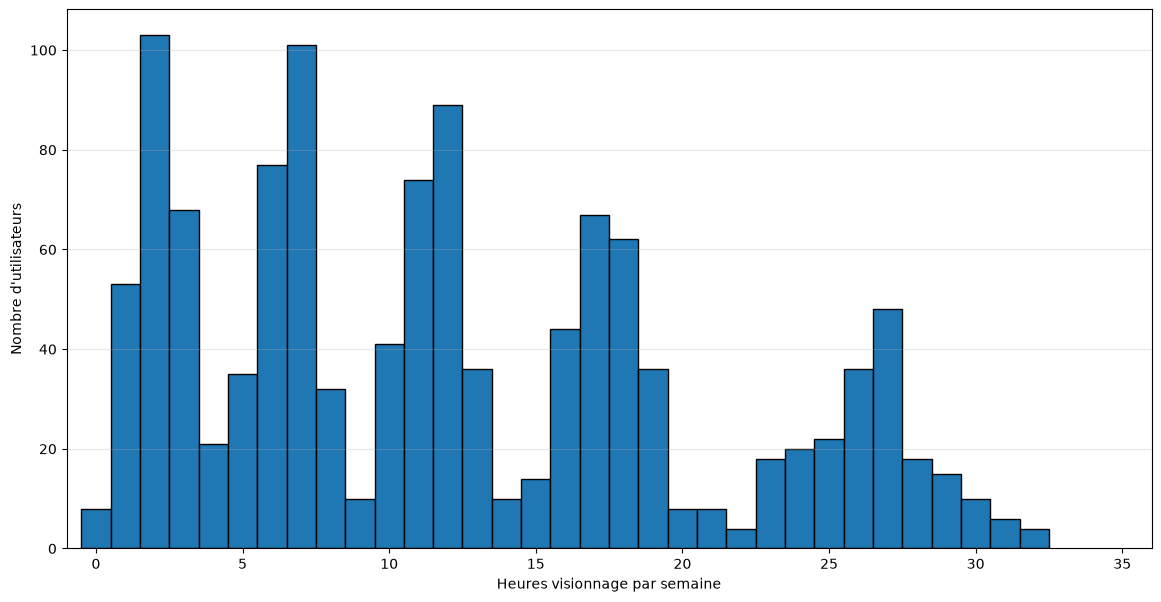

In [145]:
fig, ax = plt.subplots(1, figsize=(14,7))

ax.hist(
    heures,
    bins=range(int(heures.min()), int(heures.max())),
    align="left",
    edgecolor="black"
)

ax.set_xlabel("Heures visionnage par semaine")
ax.set_ylabel("Nombre d'utilisateurs")
ax.set_xlim(-1, 36)
ax.set_xticks(range(0, 36, 5))
ax.grid(axis="y", alpha=0.3)
plt.show()

La seule variable quantitative dans le TD est celle des heures, et quand on plot un histogramme, on voit 5 cloches / bosses = 5 modes comme les 5 modalités dans les autres variables.

On peut catégoriser de 4 façons :  (h = seuil)
1. **Amplitudes égales** = intervalles de même largeur  
⇒ ici h 7,2 / 14,0 / 20,9 / 27,7  donne effectifs 393 / 355 / 240 / 147 / 65  
⇒ déséquilibrée, coupe le pic des 7 h  

2. **Quintiles** = même effectif (de la variable) par classe  
⇒ h = 4,2 / 8,2 / 13,1 / 19,4 pour effectifs 242 / 241 / 238 / 240 / 239  
⇒ équilibrée, mais coupe les pics de 7, 12 et 18 h

3. **Seuils naturels** = seuils dans les creux (k-means 1D, Jenks)
⇒ h = 5 / 9 / 15 / 23 pour effectifs 255 / 246 / 259 / 242 / 198 
⇒ suit la structure, classes équilibrées

Bibliothèque jenkspy existe, ici calcul "à la mano" des k-means  

4. **Seuils métier** = 1, 2, 3, 4 h par jour
⇒ h = 7 / 14 / 21 / 28 pour effectifs 377 / 371 / 241 / 159 / 52  
⇒ coupe les pics ; dernière classe à 4,3 %  

##### On garde l'option des seuils naturels selon 3 critères :

Respect de la structure (creux et pics) // équilibre effectifs // lisibilité (simple à expliquer)

Un seuil naturel est une limite placée là où l’histogramme a un creux entre deux bosses. L’idée est de séparer des groupes de valeurs qui semblent naturellement distincts dans les données, plutôt que de découper l’axe en intervalles égaux ou de forcer le même nombre d’observations dans chaque classe.  

En 1 dimension, K-means et Jenks cherchent des groupes compacts : ils minimisent la dispersion des valeurs à l’intérieur des classes et peuvent aboutir à la même partition des données (algo de Jenks cherche une partition optimale). Ils peuvent donc produire des seuils proches des creux de l’histogramme, mais ils ne garantissent pas que les classes auront des effectifs égaux, ni que chaque seuil tombera précisément dans un creux. Il faut vérifier le résultat sur l’histogramme.

Parmi les cinq classes, la moins peuplée représente 16,5 % des utilisateurs et la plus peuplée 21,6 %.

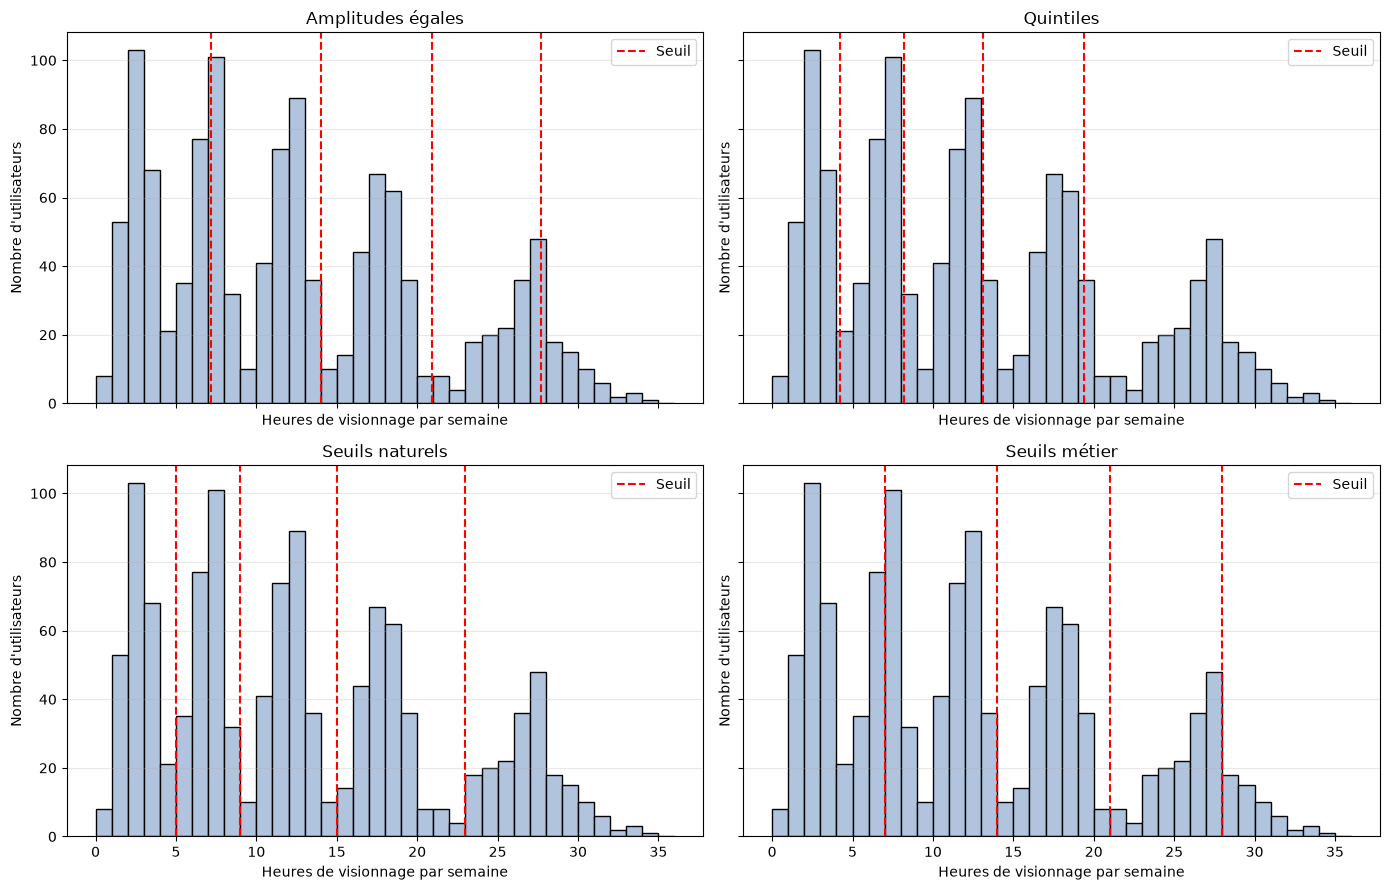

In [146]:
# Intervalles d'une heure, identiques sur les quatre graphiques
bornes_hist = np.arange(
    np.floor(heures.min()),
    np.ceil(heures.max()) + 2,
    1
)

methodes = {
    "Amplitudes égales": [7.2, 14.0, 20.9, 27.7],
    "Quintiles": [4.2, 8.2, 13.1, 19.4],
    "Seuils naturels": [5, 9, 15, 23],
    "Seuils métier": [7, 14, 21, 28],
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)

for ax, (nom, seuils) in zip(axes.flat, methodes.items()):
    ax.hist(heures, bins=bornes_hist, edgecolor="black", color="lightsteelblue")

    for i, seuil in enumerate(seuils):
        ax.axvline(
            seuil,
            color="red",
            linestyle="--",
            label="Seuil" if i == 0 else None
        )

    ax.set_title(nom)
    ax.set_xlabel("Heures de visionnage par semaine")
    ax.set_ylabel("Nombre d'utilisateurs")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

# Graduations de l'axe X tous les 5 h
debut = 5 * np.floor(heures.min() / 5)
fin = 5 * np.ceil(heures.max() / 5)
axes.flat[0].set_xticks(np.arange(debut, fin + 1, 5))

plt.tight_layout()
plt.show()

##### Version manuelle du k-means (une dimension)

In [147]:
centres_depart_kmeans = np.quantile(heures, [0.1, 0.3, 0.5, 0.7, 0.9])
# retourne les quantiles du 1er au 9eme
x = heures.to_numpy()

# _ est une convention pour une variable qu'on ne réutilise pas
for _ in range(100): 
    # [:, None] ajoute une dimension à un tableau NumPy
    # donne une matrice (lignes = utilisateurs, colonnes = centres) pour comparer chaque heure à chaque centre
    groupe_affecte = np.abs(x[:, None] - centres_depart_kmeans[None, :]).argmin(axis=1)
    # argmin récupère pour chaque utilisateur le numéro du centre le plus proche

    effectifs = np.bincount(groupe_affecte, minlength=5)
    if np.any(effectifs == 0):
        raise ValueError("Un groupe est vide : les centres doivent être réinitialisés.")

    # sélectionne les heures affectées au groupe g et calcule leur moyenne, qui devient le nouveau centre
    nouveaux_centres = np.array([
        x[groupe_affecte == g].mean()
        for g in range(5)
    ])

    if np.allclose(nouveaux_centres, centres_depart_kmeans):
        # si nouveaux centres suffisamment proches des anciens on break
        break
    centres_depart_kmeans = nouveaux_centres

if np.any(np.diff(centres_depart_kmeans) <= 0):
    raise ValueError("Les centres ne sont pas distincts : impossible de former 5 classes.")

#  pour trouver le mi-chemin entre les centres (on fait la moyenne de chaque paire) = seuil
seuils_nat = (centres_depart_kmeans[:-1] + centres_depart_kmeans[1:]) / 2  
# print(seuils_nat.round(2)) # 4,77 9,49 15,0 22,52

modalites = [
    "Usage_faible",
    "Usage_modere",
    "Usage_regulier",
    "Usage_soutenu",
    "Usage_intensif"
]

df_base["Usage"] = pd.cut(
    heures,
    bins=[-np.inf, *seuils_nat, np.inf],
    labels=modalites,
    right=True # inclut borne droite
)

effectifs = df_base["Usage"].value_counts(sort=False)
# compte les utilisateurs de chaque modalité
pourcentages = ((effectifs / heures.size) * 100).round(1)

print(pd.DataFrame({
    "Effectif": effectifs,
    "Pourcentage": pourcentages
}))

                Effectif  Pourcentage
Usage                                
Usage_faible         248         20.7
Usage_modere         256         21.3
Usage_regulier       254         21.2
Usage_soutenu        240         20.0
Usage_intensif       202         16.8


##### Sélection variables actives

In [148]:
var_actives = ["Usage"] + var_qualitatives
df_act = df_base[var_actives].copy()

display(df_act)

n_a, p_a = df_act.shape

print(n_a, p_a)

,Usage,Abonnement,Genre_prefere,Appareil,Moment_visionnage,Partage_compte
ID_utilisateur,,,,,,
JS0001,Usage_modere,Essentiel,Sport,Smartphone,Trajets,Solo
JS0002,Usage_modere,Essentiel,Animation,Tablette,Soiree,Famille_elargie
JS0003,Usage_regulier,Famille,Animation,Tablette,Soiree,Famille_elargie
JS0004,Usage_faible,Essentiel,Films,Smartphone,Trajets,Solo
JS0005,Usage_modere,Gratuit,Films,Box_TV,Week-end,Solo
...,...,...,...,...,...,...
JS1196,Usage_soutenu,Famille,Documentaires,TV_connectee,Apres-midi,Couple
JS1197,Usage_regulier,Essentiel,Documentaires,Smartphone,Soiree,Colocation
JS1198,Usage_regulier,Essentiel,Sport,Smartphone,Soiree,Amis


1200 6


#### Modalités rares ?

##### Définitions

**L’inertie = la dispersion du nuage**

En ACM, chaque individu et chaque modalité (un point sur son axe meme si origine sur le deuxième, ...) est représenté par un point.    
L’inertie mesure la dispersion de ces points autour du centre du nuage, selon une distance particulière appelée distance du khi-deux.  

Si les points sont très regroupés, l’inertie est faible.  
S’ils sont davantage dispersés, l’inertie est élevée.  
*C’est une idée proche de la variance en analyse de données, mais l’ACM utilise sa propre géométrie et ses pondérations.*

**L’inertie portée par un axe » est une façon imagée de parler de la dispersion des points quand on les projette sur cet axe**

On imagine le nuage de points de l’ACM et une droite qui passe par son centre.  
On projette chaque point sur cette droite, comme si on regardait son ombre. Si les projections sont très dispersées, la droite résume bien une partie de la structure du nuage : elle a une forte inertie projetée. Si elles sont regroupées près du centre, elle en résume peu.

L’ACM choisit donc comme premier axe la direction pour laquelle cette dispersion projetée est la plus grande.  
Le deuxième axe est perpendiculaire au premier et maximise la dispersion restante, et ainsi de suite.  
La valeur propre $\lambda_\alpha$ mesure la dispersion projetée sur l’axe $\alpha$, selon les pondérations propres à l’ACM.

Quelle part de la dispersion des données est résumée par cet axe ?

**Les valeurs propres = l'inertie portée par chaque axe**

L’ACM construit des axes qui résument cette dispersion :

    - le premier axe est celui qui porte le plus d’inertie possible   
    - le deuxième porte autant d’inertie que possible parmi les directions restantes tout en étant perpendiculaire au premier  
    - les axes suivants continuent ainsi

La valeur propre $\lambda_\alpha$ indique combien d’inertie est portée par l’axe $\alpha$.  
Donc, plus $\lambda_\alpha$ est grande, plus cet axe résume de dispersion du nuage.

##### Formules 

Dans une ACM, chaque modalité (dans une variable) est représentée comme un point.  
Sa fréquence (fq) est la proportion d’individus qui possèdent cette modalité.

**Fréquence**
$$ fq = \frac{n}{N}$$
$ n =$ effectif (nombre individus) modalité  
$ N =$ nombre de lignes (total d'individus)

**Distance² au centre du nuage**  
$$d² = \frac{1}{fq} - 1 
= \frac{1 - fq}{fq}$$

C’est une distance au sens du khi-deux, pas une distance en heures ou dans une unité concrète.

**Inertie de la modalité** 
$$\frac{1 - fq}{p}$$

$p =$ nombre de variables actives (colonnes) de l'ACM.

**Inertie de la variable (j) = la somme des inerties de ses modalités** 
$$
I_j
= \sum_{k=1}^{m_j} I_{jk}
= \sum_{k=1}^{m_j} \frac{1-f_{jk}}{p}
$$
$$
= \frac{1}{p}
  \left(
    \sum_{k=1}^{m_j} 1
    -
    \sum_{k=1}^{m_j} f_{jk}
  \right)
$$
(Pour rappel, la somme des fréquences = 1)
$$
\boxed{I_j = \frac{m_j-1}{p}}
$$

**Inertie totale = somme des inerties de toutes les variable = la somme des inerties de toutes les modalités** 

$$
I_{\text{totale}}
= \frac{\sum_{j=1}^{p}m_j-p}{p}.
$$

En posant $K = \sum_{j=1}^{p}m_j$, le nombre total de modalités, on obtient :

$$
= \frac{K-p}{p} 
= \frac{K}{p} - \frac{p}{p}
$$

$$\boxed{I_{\text{totale}} = \frac{K}{p} - 1}

Exemple sur la modalité "console" 
(*fréquence connue plus haut grâce à `.value_counts(normalize=True)`*)  

$fq = 0,0308 \simeq 3,1$ %  
soit environ 37 personnes sur les 1 200

$d² = \frac{1}{0,038 - 1} = 25,32 $ 

Avec les 6 variables = inertie  
$d² = \frac{1 - 0,038 }{6} \simeq 00,16$ 

0,16 **n’est pas** 16 % de l’inertie totale : c’est **sa contribution** à l’inertie du nuage selon cette formule.  
Plus une modalité est rare, plus elle est loin du centre.
Elle est la plus forte parmi les 31 modalités, mais cela ne signifie pas automatiquement qu’elle contribue le plus à chacun des axes de l’ACM.  

Une modalité rare est plus éloignée du centre et son inertie individuelle augmente, mais cette inertie reste limitée par la fréquence et la convention de calcul.  
Malgré tout, l'ACM implique une inertie faible, cela peut-être trompeur et doit être pris en compte / corrigé.

##### Critères sélection modalités d'une variable / colonne

(rappel : la somme des fréquences = 1)

- Avant l'ACM 
 
        └── chaque modalité devrait être ≥ 5 % des individus. 
        
        └── les variables doivent avoir un nombre de modalités proche (à peu près égale, sinon une variable avec plus de modalités "pèse plus" sur l'inertie totale des variables dans l'ACM).

        ⇒ correction : ventiler (regrouper avec une modalité proche) / regrouper des modalités, toutefois de façon cohérente !

- Pendant la lecture d'un axe  

        └── la contribution d'une modalité à un axe :  
        Les contributions des modalités totalisent 100 % pour chaque axe.  
        Contribution moyenne = 100 / total modalités toutes les variables (%), ici par exemple pour 30 modalités, la contribution moyenne est de 3,33 %.  

        Si la contribution de la modalité > contribution moyenne, signale alors que la modalité participe plus que la moyenne à la construction de l'axe VS pas nécessairement une modalité « importante » pour toute l’analyse.

        └── la significativité d'une modalité : | valeur - test | > 2 
        Repère usuel (règle approximative, pas une preuve) pour savoir si une association est assez notable entre une modalité et un côté de l'axe.

- Pendant la lecture du plan

        └── la qualité de la modalité : cos² par rapport au taux brut du plan.
        cos² mesure à quel point la position d’une modalité est bien représentée par le plan (les axes).  
        Un cos² supérieur suggère une représentation meilleure que ce repère, et un cos² faible invite à interpréter la position avec prudence.


1. Contribution d’une modalité ($k$) à un axe $\alpha$ :
$$Ctr_{k\alpha} = \frac {m_kF²_{k\alpha}} {\lambda_\alpha} \times 100$$


Sachant que $m_k$ est la masse de la modalité = $\frac{fq}{Q}$ ($Q$ = nombres variables active)  
$F²_{k\alpha}$ = sa coordonnée sur l'axe ${\alpha}$  
$\lambda_\alpha$ = la valeur propre de cet axe ${\alpha}$

2. Valeur-test $(\lvert\operatorname{VT}\rvert>2)$ : 

mesure si les individus ayant une modalité donnée ont des coordonnées sur l’axe qui s’écartent nettement de celles de l’ensemble des individus.
Formule maths complexe et détails du calcul peuvent varier selon convention et logiciel. Aussi ce calcul nécessite de connaître les coordonnées factorielles des individus pas seulement celles des modalités, mais le signe indique de quel côté de l'axe se situe la modalité. 

3. Cos² et qualité sur le plan :

mesure si la position d'une modalité ($k$) est bien représentée 
    - sur un axe $(\alpha)$ :  
    $$cos²_{k\alpha} = \frac {F²_{k\alpha}}{d²_k}$$  
    - sur un plan formé par les axes 1 et 2 :  
    $$cos²_{k,(1,2)} = \frac {F²_{k1} + F²_{k2}}{d²_k}$$  

Les cos² sont compris entre 0 et 1, et plus ils sont élevés ⇒ mieux la position est représentée sur l'axe / le plan.

Le **taux brut du plan** = part de l'inertie totale expliquée par deux axes :
    $$= \frac {\lambda_1 + \lambda_2}{\sum_\alpha {\lambda_\alpha}} \times 100$$  

Un taux brut de 26 % signifie que les axes 1 et 2 réunis portent (explique) 26 % de l’inertie totale VS n’est pas le cos² de chaque modalité.  
Comparer le cos² d’une modalité à 26 % donne un repère global, mais pour décider si cette modalité est bien représentée, il faut regarder son propre cos² sur le plan.


##### 

#### Ventilation modalité (*cf.* section modalités rare ? pour comprendre comment choisir)

##### Contrôle des modalités

In [149]:
# n_a = nombre individus
# p_a = nombre variables actives

lignes = []
for va in var_actives:
    for modalite, effectif in df_act[va].value_counts().items():
        frequence = effectif / n_a
        inertie = (1 - frequence) / p_a

        lignes.append([
            va,
            modalite,
            effectif,
            frequence * 100,
            inertie
        ])

controle = pd.DataFrame(
    lignes,
    columns=["Variable", "Modalité", "Effectif", "%", "Inertie"]
    )

controle["Statut"] = np.where(
    controle["%"] < 5,
    "À VENTILER",
    "_")
 
display(controle)

,Variable,Modalité,Effectif,%,Inertie,Statut
0,Usage,Usage_modere,256,21.333333,0.131111,_
1,Usage,Usage_regulier,254,21.166667,0.131389,_
2,Usage,Usage_faible,248,20.666667,0.132222,_
3,Usage,Usage_soutenu,240,20.000000,0.133333,_
4,Usage,Usage_intensif,202,16.833333,0.138611,_
5,Abonnement,Essentiel,285,23.750000,0.127083,_
6,Abonnement,Premium,254,21.166667,0.131389,_
7,Abonnement,Famille,225,18.750000,0.135417,_
8,Abonnement,Standard,219,18.250000,0.136250,_
9,Abonnement,Gratuit,217,18.083333,0.136528,_


##### Ventilation

In [150]:
# Regroupe les deux modalités dans le DataFrame utilisé pour l'ACM

df_act["Appareil"] = df_act["Appareil"].replace(
    {"Console": "TV_connectee"}
)

print(df_act["Appareil"].value_counts())
print("-" * 50)
print(f"% effectif dans les modalités ventilées\n\n{(df_act["Appareil"].value_counts() / len(df_act) * 100).round(1)}")

Appareil
TV_connectee    284
Box_TV          274
Smartphone      231
Tablette        209
Ordinateur      202
Name: count, dtype: int64
--------------------------------------------------
% effectif dans les modalités ventilées

Appareil
TV_connectee    23.7
Box_TV          22.8
Smartphone      19.2
Tablette        17.4
Ordinateur      16.8
Name: count, dtype: float64


##### Équilibre entre les variables et modalités

In [151]:
if df_act.isna().any().any():
    raise ValueError(
        "df_act contient des valeurs manquantes : "
        "il faut décider comment les traiter avant le calcul."
    )

lignes = []

for variable in df_act.columns:
    # pour chaque modalité :
    effectifs = df_act[variable].value_counts()
    frequences = effectifs / n_a
    nb_modalites = len(effectifs)

    # inertie variable = somme des inerties des modalités 
    # inertie_variable = ((1 - frequences) / p_a).sum()
    inertie_variable = (nb_modalites - 1) / p_a

    lignes.append({
        "Variable": variable,
        "Nombre_modalites": nb_modalites,
        "Inertie_variable": inertie_variable,
        "Part_inertie_totale_%" : pd.NA,
        "Effectif_min_%": frequences.min() * 100
    })

controle_equilibre = pd.DataFrame(lignes)

# Somme des inerties variables = inertie totale
inertie_totale = controle_equilibre["Inertie_variable"].sum()

controle_equilibre["Part_inertie_totale_%"] = (
    controle_equilibre["Inertie_variable"] / inertie_totale * 100
)

# Arrondit pour affichage
controle_equilibre = controle_equilibre.round({
    "Inertie_variable": 3,
    "Part_inertie_totale_%": 1,
    "Effectif_min_%": 1
})

display(controle_equilibre)

,Variable,Nombre_modalites,Inertie_variable,Part_inertie_totale_%,Effectif_min_%
0,Usage,5,0.667,16.7,16.8
1,Abonnement,5,0.667,16.7,18.1
2,Genre_prefere,5,0.667,16.7,17.6
3,Appareil,5,0.667,16.7,16.8
4,Moment_visionnage,5,0.667,16.7,17.8
5,Partage_compte,5,0.667,16.7,15.9


#### V de Cramer

Le V de Cramer mesure la force de l’association entre deux variables catégorielles.  
Dans ce contexte, il pourrait par exemple mesurer si le type d’Appareil est associé au Moment_visionnage.

Il se calcule à partir du test du khi-deux :
$$
V = \sqrt{\frac{\chi^2}{n \min{(r - 1, c -1)}}}
$$

$\chi^2$ est la statistique du test du khi-deux  
$n$ est le nombre d'observations  
$r$ et $c$ sont les nombres de modalités des deux variables  

**Le V varie de 0 à 1 :**  
⇒ proche de 0 : peu ou pas d’association observée  
⇒ plus élevé : association plus forte

In [152]:
# exemple entre les variables, Appareil et Moment de visionnage

table = pd.crosstab(df_act["Appareil"], df_act["Moment_visionnage"])
print(table)
chi2, p_value, ddl, effectifs_theoriques = chi2_contingency(table)

n = table.to_numpy().sum()
r, c = table.shape

v_cramer = np.sqrt(
    chi2 / (n * min(r - 1, c - 1))
)

print(f"V de Cramer : {v_cramer:.3f}")
print(f"p-value du test du khi-deux : {p_value:.4g}")

Moment_visionnage  Apres-midi  Nuit  Soiree  Trajets  Week-end
Appareil                                                      
Box_TV                     35    17      95       79        48
Ordinateur                 52    89      24       16        21
Smartphone                 19    19      52      120        21
TV_connectee              113    70      34       23        44
Tablette                   49    18      39       17        86
V de Cramer : 0.320
p-value du test du khi-deux : 2.801e-94


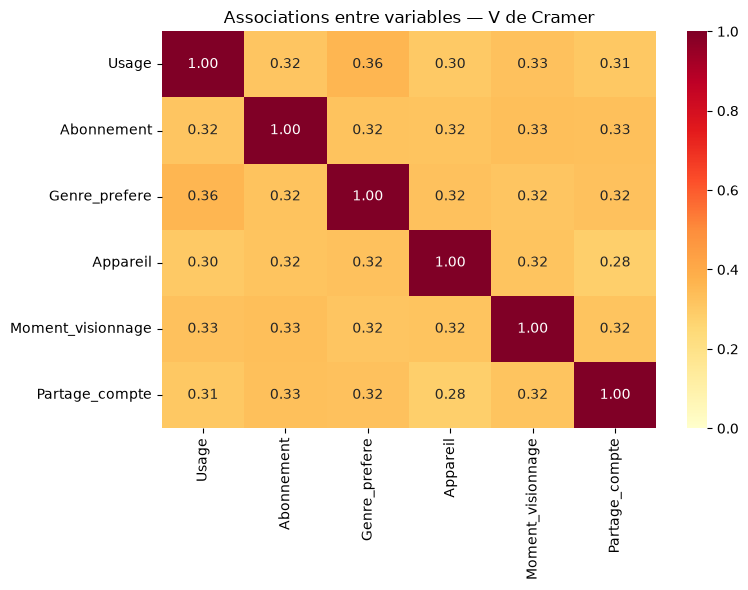

In [168]:
variables =  list(df_act.columns)
matrice_var = pd.DataFrame(
    np.eye(len(variables)), # renvoi un tableau 2D avec 1 en diag et 0 ailleurs
    index=variables,
    columns=variables,
    dtype=float
)
for index, variable_1 in enumerate(variables):
    for variable_2 in variables[index + 1:]:
        # construction des paires
        paire = df_act[[variable_1, variable_2]].dropna()
        table = pd.crosstab(paire[variable_1], paire[variable_2])

        r, c = table.shape

        # Le V n'est pas défini si l'une des variables n'a qu'une modalité.
        if min(r - 1, c - 1) == 0:
            v = np.nan
        else:
            chi2, *_ = chi2_contingency(table)
            n = table.to_numpy().sum()
            v = np.sqrt(chi2 / (n * min(r - 1, c - 1)))

        # .loc[ligne, colonne] on associe la valeur du V de Cramer // matrice symétrique
        matrice_var.loc[variable_1, variable_2] = v
        matrice_var.loc[variable_2, variable_1] = v

plt.figure(figsize=(8, 6))
sns.heatmap(
    matrice_var,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0,
    vmax=1
)
plt.title("Associations entre variables — V de Cramer")
plt.tight_layout()
plt.show()

Aucune paire ne domine, liaisons homogènes, aucune variable isolée et chacune pourra participer à la cosntruction des axes.
La plus forte est celle entre usage et genre.

#### QUEPUICK

Seules les variables actives construisent les axes. Les supplémentaires sont projetées après coup pour aider à interpréter.

Les six variables décrivent toutes l'usage de la plateforme : elles sont actives. Les heures brutes, quantitatives, entrent sous forme catégorisée.

Six variables équilibrées : aucune dimension n'est sur-pondérée, et chaque profil pourra être décrit sur les six variables.

⇒ les heures brutes servent ensuite d'illustration : on calcule les heures moyennes de chaque profil.

In [ ]:
# SLIDE 17 